# Proyek Analisis Data: Analisis Performa Penjualan, Perilaku Pelanggan, dan Distribusi Geografis pada Brazilian E-Commerce Olist
- **Nama:** Annisa Ramadhani
- **Email:** DS284B6X0213@student.devacademy.id
- **ID Dicoding:** DS284B6X0213

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren jumlah pesanan berstatus delivered dan total nilai pembayaran pelanggan Olist setiap bulan selama periode September 2016 hingga Oktober 2018, serta bulan mana yang menunjukkan performa tertinggi dan terendah?
- **Pertanyaan 2:** Bagaimana distribusi pelanggan Olist berdasarkan segmentasi Recency, Frequency, dan Monetary (RFM) dari transaksi yang berstatus delivered selama periode September 2016 hingga Oktober 2018, dan segmen pelanggan mana yang perlu diprioritaskan dalam strategi retensi?
- **Pertanyaan 3:** Bagaimana persebaran jumlah pelanggan dan pesanan berstatus delivered di setiap negara bagian Brasil selama periode September 2016 hingga Oktober 2018, serta wilayah mana yang berpotensi menjadi prioritas pengembangan pasar?

## Import Semua Packages/Library yang Digunakan

### Import Library yang Dibutuhkan

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import geopandas as gpd
import folium

import os
import zipfile
import warnings

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

warnings.filterwarnings('ignore')

print("All libraries have been successfully imported!")

All libraries have been successfully imported!


## Data Wrangling

### Gathering Data

#### Load All Datasets

#### Memuat Sembilan Dataset Brazilian E-Commerce Olist

In [ ]:
import os
import pandas as pd

DATA_DIR = '/content'

file_names = {
    'customers': 'customers_dataset.csv',
    'orders': 'orders_dataset.csv',
    'order_items': 'order_items_dataset.csv',
    'payments': 'order_payments_dataset.csv',
    'reviews': 'order_reviews_dataset.csv',
    'products': 'products_dataset.csv',
    'sellers': 'sellers_dataset.csv',
    'geolocation': 'geolocation_dataset.csv',
    'category_translation': 'product_category_name_translation.csv'
}

dataframes = {}

for name, file_name in file_names.items():
    file_path = os.path.join(DATA_DIR, file_name)
    dataframes[name] = pd.read_csv(file_path)
    print(f'{name}: {dataframes[name].shape}')

customers_df = dataframes['customers']
orders_df = dataframes['orders']
order_items_df = dataframes['order_items']
payments_df = dataframes['payments']
reviews_df = dataframes['reviews']
products_df = dataframes['products']
sellers_df = dataframes['sellers']
geolocation_df = dataframes['geolocation']
category_translation_df = dataframes['category_translation']

print("\nSemua dataset berhasil dimuat!")

customers: (99441, 5)
orders: (99441, 8)
order_items: (112650, 7)
payments: (103886, 5)
reviews: (99224, 7)
products: (32951, 9)
sellers: (3095, 4)
geolocation: (1000163, 5)
category_translation: (71, 2)

Semua dataset berhasil dimuat!


**Insight:**
- Seluruh sembilan dataset Brazilian E-Commerce Olist berhasil dimuat tanpa kendala.
- Dataset terdiri dari informasi pelanggan, pesanan, item pesanan, pembayaran, ulasan, produk, penjual, geolokasi, dan terjemahan kategori produk.
- Dataset geolocation memiliki jumlah baris terbesar, yaitu 1.000.163 baris, sedangkan dataset category translation memiliki jumlah baris terkecil, yaitu 71 baris.
- Seluruh dataset akan digunakan sesuai kebutuhan untuk menganalisis performa penjualan, perilaku pelanggan, dan distribusi geografis.

### Assessing Data

#### Identifying Data Quality Problems

#### Memeriksa Struktur dan Informasi Setiap Dataset

In [ ]:
for name, df in dataframes.items():
    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")
    print(f"Jumlah baris dan kolom: {df.shape}")
    print("\nInformasi dataset:")
    df.info()


DATASET: CUSTOMERS
Jumlah baris dan kolom: (99441, 5)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

DATASET: ORDERS
Jumlah baris dan kolom: (99441, 8)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                

#### Merangkum Missing Values dan Data Duplikat

In [ ]:
# Memeriksa jumlah missing values dan duplicate data

quality_summary = []

for name, df in dataframes.items():
    quality_summary.append({
        'Dataset': name,
        'Missing Values': df.isna().sum().sum(),
        'Duplicate Rows': df.duplicated().sum()
    })

quality_df = pd.DataFrame(quality_summary)

display(quality_df)

,Dataset,Missing Values,Duplicate Rows
0,customers,0,0
1,orders,4908,0
2,order_items,0,0
3,payments,0,0
4,reviews,145903,0
5,products,2448,0
6,sellers,0,0
7,geolocation,0,261831
8,category_translation,0,0


#### Mengidentifikasi Missing Values pada Setiap Dataset

In [ ]:
# Memeriksa detail missing values pada setiap dataset

for name, df in dataframes.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        print(f"\n{'='*60}")
        print(f"DATASET: {name.upper()}")
        print(f"{'='*60}")

        missing_detail = pd.DataFrame({
            'Missing Values': missing,
            'Percentage (%)': (
                missing / len(df) * 100
            ).round(2)
        })

        display(missing_detail)


DATASET: ORDERS


,Missing Values,Percentage (%)
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98



DATASET: REVIEWS


,Missing Values,Percentage (%)
review_comment_title,87656,88.34
review_comment_message,58247,58.70



DATASET: PRODUCTS


,Missing Values,Percentage (%)
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


#### Memeriksa Duplikasi pada Kolom Primary Key

In [ ]:
# Memeriksa duplikasi berdasarkan primary key

key_columns = {
    'customers': ['customer_id'],
    'orders': ['order_id'],
    'order_items': ['order_id', 'order_item_id'],
    'payments': ['order_id', 'payment_sequential'],
    'reviews': ['review_id'],
    'products': ['product_id'],
    'sellers': ['seller_id'],
    'category_translation': ['product_category_name']
}

for name, columns in key_columns.items():
    df = dataframes[name]

    duplicate_count = df.duplicated(
        subset=columns
    ).sum()

    print(f"{name}: {duplicate_count} duplicate key(s)")

customers: 0 duplicate key(s)
orders: 0 duplicate key(s)
order_items: 0 duplicate key(s)
payments: 0 duplicate key(s)
reviews: 814 duplicate key(s)
products: 0 duplicate key(s)
sellers: 0 duplicate key(s)
category_translation: 0 duplicate key(s)


#### Mengidentifikasi Duplikasi review_id

In [ ]:
# Memeriksa detail duplikasi review_id

duplicate_reviews = reviews_df[
    reviews_df.duplicated(subset=['review_id'], keep=False)
].sort_values('review_id')

print("Jumlah baris dengan review_id duplikat:",
      len(duplicate_reviews))

print("\nJumlah review_id yang mengalami duplikasi:",
      duplicate_reviews['review_id'].nunique())

print("\nContoh data review yang memiliki ID duplikat:")
display(duplicate_reviews.head(20))

Jumlah baris dengan review_id duplikat: 1603

Jumlah review_id yang mengalami duplikasi: 789

Contoh data review yang memiliki ID duplikat:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


#### Menganalisis Relasi review_id dengan order_id

In [ ]:
# Memeriksa hubungan review_id dengan order_id

review_duplicate_analysis = (
    duplicate_reviews.groupby('review_id')
    .agg(
        jumlah_baris=('order_id', 'size'),
        jumlah_order=('order_id', 'nunique'),
        jumlah_review_score=('review_score', 'nunique')
    )
    .reset_index()
)

display(review_duplicate_analysis.head(20))

print("\nDistribusi jumlah pesanan per review_id duplikat:")
display(
    review_duplicate_analysis['jumlah_order']
    .value_counts()
    .sort_index()
)

,review_id,jumlah_baris,jumlah_order,jumlah_review_score
0,00130cbe1f9d422698c812ed8ded1919,2,2,1
1,0115633a9c298b6a98bcbe4eee75345f,2,2,1
2,0174caf0ee5964646040cd94e15ac95e,2,2,1
3,017808d29fd1f942d97e50184dfb4c13,2,2,1
4,0254bd905dc677a6078990aad3331a36,2,2,1
5,0288d42bef3dfe36930740c9588a570f,2,2,1
6,02aa7f5f75e964e3c7efa59a1f515281,2,2,1
7,034528cb00b6bc981847acafbdf2ae0b,2,2,1
8,03a6a25db577d0689440933055111897,2,2,1
9,0467560f511c516ddaa54a60edb0c291,2,2,1



Distribusi jumlah pesanan per review_id duplikat:


,count
jumlah_order,
2,764
3,25


#### Memeriksa Konsistensi Data pada review_id Duplikat

In [ ]:
# Memeriksa konsistensi informasi pada review_id yang duplikat

review_consistency = (
    duplicate_reviews.groupby('review_id')
    .agg(
        jumlah_order=('order_id', 'nunique'),
        variasi_score=('review_score', 'nunique'),
        variasi_judul=('review_comment_title', 'nunique'),
        variasi_komentar=('review_comment_message', 'nunique'),
        variasi_tanggal_review=('review_creation_date', 'nunique'),
        variasi_tanggal_jawaban=('review_answer_timestamp', 'nunique')
    )
    .reset_index()
)

print("Jumlah review_id dengan isi yang tidak konsisten:")

for column in review_consistency.columns[2:]:
    print(
        f"{column}: "
        f"{(review_consistency[column] > 1).sum()}"
    )

print("\nPemeriksaan order_id yang memiliki lebih dari satu baris review:")
print(
    "Jumlah order_id duplikat:",
    reviews_df['order_id'].duplicated().sum()
)

Jumlah review_id dengan isi yang tidak konsisten:
variasi_score: 0
variasi_judul: 0
variasi_komentar: 0
variasi_tanggal_review: 0
variasi_tanggal_jawaban: 0

Pemeriksaan order_id yang memiliki lebih dari satu baris review:
Jumlah order_id duplikat: 551


#### Mengidentifikasi order_id yang Muncul Lebih dari Sekali pada Dataset Reviews

In [ ]:
# Memeriksa detail order_id yang muncul lebih dari satu kali

duplicate_order_reviews = reviews_df[
    reviews_df.duplicated(subset=['order_id'], keep=False)
].sort_values('order_id')

print("Jumlah baris yang memiliki order_id duplikat:",
      len(duplicate_order_reviews))

print("Jumlah order_id unik yang duplikat:",
      duplicate_order_reviews['order_id'].nunique())

display(duplicate_order_reviews.head(20))

Jumlah baris yang memiliki order_id duplikat: 1098
Jumlah order_id unik yang duplikat: 547


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,NaN,NaN,2017-08-29 00:00:00,2017-08-30 01:59:12
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,NaN,Estou acostumada a comprar produtos pelo barat...,2017-08-25 00:00:00,2017-08-29 21:45:57
22779,ab30810c29da5da8045216f0f62652a2,013056cfe49763c6f66bda03396c5ee3,5,NaN,NaN,2018-02-22 00:00:00,2018-02-23 12:12:30
68633,73413b847f63e02bc752b364f6d05ee9,013056cfe49763c6f66bda03396c5ee3,4,NaN,NaN,2018-03-04 00:00:00,2018-03-05 17:02:00
854,830636803620cdf8b6ffaf1b2f6e92b2,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30 00:00:00,2018-01-02 10:54:06
83224,d8e8c42271c8fb67b9dad95d98c8ff80,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30 00:00:00,2018-01-02 10:54:47
17582,017f0e1ea6386de662cbeba299c59ad1,02355020fd0a40a0d56df9f6ff060413,1,NaN,ja reclamei varias vezes e ate hoje não sei on...,2018-03-29 00:00:00,2018-03-30 03:16:19
89888,0c8e7347f1cdd2aede37371543e3d163,02355020fd0a40a0d56df9f6ff060413,3,NaN,UM DOS PRODUTOS (ENTREGA02) COMPRADOS NESTE PE...,2018-03-21 00:00:00,2018-03-22 01:32:08
55137,61fe4e7d1ae801bbe169eb67b86c6eda,029863af4b968de1e5d6a82782e662f5,4,NaN,NaN,2017-07-19 00:00:00,2017-07-20 12:06:11
37911,04d945e95c788a3aa1ffbee42105637b,029863af4b968de1e5d6a82782e662f5,5,NaN,NaN,2017-07-14 00:00:00,2017-07-17 13:58:06


#### Menghitung Jumlah Review pada Setiap Pesanan

In [ ]:
# Menganalisis jumlah review pada setiap order_id

order_review_count = (
    reviews_df.groupby('order_id')
    .agg(
        jumlah_review=('review_id', 'size'),
        jumlah_review_id=('review_id', 'nunique')
    )
    .reset_index()
)

print("Distribusi jumlah baris review per order:")
display(order_review_count['jumlah_review'].value_counts().sort_index())

print("\nDistribusi jumlah review_id unik per order:")
display(order_review_count['jumlah_review_id'].value_counts().sort_index())

print("\nJumlah order dengan lebih dari satu review_id:")
print((order_review_count['jumlah_review_id'] > 1).sum())

Distribusi jumlah baris review per order:


,count
jumlah_review,
1,98126
2,543
3,4



Distribusi jumlah review_id unik per order:


,count
jumlah_review_id,
1,98126
2,543
3,4



Jumlah order dengan lebih dari satu review_id:
547


#### Memeriksa Duplikasi Baris pada Dataset Geolocation

In [ ]:
# Memeriksa duplikasi pada dataset geolocation

duplicate_geolocation = geolocation_df[
    geolocation_df.duplicated(keep=False)
]

print("Jumlah baris yang terlibat dalam duplikasi:",
      len(duplicate_geolocation))

print("Jumlah baris duplikat selain kemunculan pertama:",
      geolocation_df.duplicated().sum())

print("\nContoh baris geolocation yang duplikat:")
display(duplicate_geolocation.head(20))

Jumlah baris yang terlibat dalam duplikasi: 390005
Jumlah baris duplikat selain kemunculan pertama: 261831

Contoh baris geolocation yang duplikat:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP
6,1047,-23.55,-46.64,sao paulo,SP
7,1013,-23.55,-46.63,sao paulo,SP
8,1029,-23.54,-46.63,sao paulo,SP
9,1011,-23.55,-46.64,sao paulo,SP
10,1013,-23.55,-46.63,sao paulo,SP
13,1012,-23.55,-46.63,sao paulo,SP
15,1046,-23.55,-46.64,sao paulo,SP


#### Memeriksa Jumlah Koordinat Unik Berdasarkan Kode Pos

In [ ]:
# Memeriksa jumlah koordinat unik untuk setiap kode pos

geolocation_zip_analysis = (
    geolocation_df.groupby('geolocation_zip_code_prefix')
    .agg(
        jumlah_koordinat=('geolocation_lat', 'nunique'),
        jumlah_longitude=('geolocation_lng', 'nunique'),
        jumlah_kota=('geolocation_city', 'nunique'),
        jumlah_state=('geolocation_state', 'nunique')
    )
    .reset_index()
)

print("Jumlah kode pos unik:",
      geolocation_df['geolocation_zip_code_prefix'].nunique())

print("\nKode pos dengan lebih dari satu koordinat latitude:")
print((geolocation_zip_analysis['jumlah_koordinat'] > 1).sum())

print("\nKode pos dengan lebih dari satu kota:")
print((geolocation_zip_analysis['jumlah_kota'] > 1).sum())

print("\nKode pos dengan lebih dari satu state:")
print((geolocation_zip_analysis['jumlah_state'] > 1).sum())

Jumlah kode pos unik: 19015

Kode pos dengan lebih dari satu koordinat latitude:
17781

Kode pos dengan lebih dari satu kota:
8556

Kode pos dengan lebih dari satu state:
8


**Steps to Take:**
- Mengonversi kolom tanggal yang masih bertipe object menjadi datetime agar dapat digunakan dalam analisis berbasis waktu.
- Memeriksa missing values pada dataset orders berdasarkan status pesanan. Missing values yang berkaitan dengan proses pesanan yang belum selesai atau dibatalkan dipertahankan sebagai NaT.
- Mempertahankan missing values pada dataset products karena atribut tersebut tidak menjadi fokus analisis utama.
- Menghapus baris duplikat identik pada dataset geolocation menggunakan `drop_duplicates()` untuk mengurangi redundansi data.
- Mempertahankan data pada dataset reviews yang memiliki duplikasi `review_id` maupun `order_id` karena belum terdapat bukti bahwa baris-baris tersebut tidak valid.
- Memastikan dataset yang telah dibersihkan tetap konsisten dan siap digunakan dalam analisis penjualan, segmentasi pelanggan, dan distribusi geografis.


**Insight:**
- Dataset geolocation memiliki jumlah duplikasi baris identik yang cukup besar, yaitu 261.831 baris, sehingga perlu dilakukan penghapusan duplikasi.
- Dataset orders, reviews, dan products memiliki missing values dengan karakteristik berbeda sehingga penanganannya perlu disesuaikan dengan konteks setiap kolom.
- Dataset reviews menunjukkan relasi yang tidak sepenuhnya unik antara review_id dan order_id, sehingga data perlu dipertahankan secara hati-hati agar informasi ulasan tidak hilang.
- Sebagian kolom tanggal masih bertipe object, sehingga perlu dikonversi sebelum digunakan dalam analisis tren waktu.

### Cleaning Data

#### Memperbaiki Masalah Kualitas Data


#### Mengonversi Kolom Tanggal ke Tipe Datetime

In [ ]:
# Mengubah kolom tanggal menjadi datetime

date_columns = {
    'orders': [
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ],
    'order_items': [
        'shipping_limit_date'
    ],
    'reviews': [
        'review_creation_date',
        'review_answer_timestamp'
    ]
}

for name, columns in date_columns.items():
    for column in columns:
        dataframes[name][column] = pd.to_datetime(
            dataframes[name][column],
            errors='coerce'
        )

print("Konversi tipe data tanggal selesai.")

for name, columns in date_columns.items():
    print(f"\n{name.upper()}")
    display(dataframes[name][columns].dtypes)

Konversi tipe data tanggal selesai.

ORDERS


,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]



ORDER_ITEMS


,0
shipping_limit_date,datetime64[ns]



REVIEWS


,0
review_creation_date,datetime64[ns]
review_answer_timestamp,datetime64[ns]


#### Memeriksa Missing Values Tanggal Berdasarkan Status Pesanan

In [ ]:
# Memeriksa missing values berdasarkan status pesanan

date_order_columns = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

missing_by_status = (
    orders_df.groupby('order_status')[date_order_columns]
    .apply(lambda x: x.isna().sum())
)

display(missing_by_status)

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


#### Menghapus Duplikasi Identik pada Dataset Geolocation

In [ ]:
# Menghapus baris duplikat identik pada dataset geolocation

geolocation_df = geolocation_df.drop_duplicates()

print("Jumlah baris setelah menghapus duplikasi:", len(geolocation_df))
print("Jumlah duplikasi tersisa:", geolocation_df.duplicated().sum())

Jumlah baris setelah menghapus duplikasi: 738332
Jumlah duplikasi tersisa: 0


#### Memeriksa Kondisi Dataset Setelah Cleaning

In [ ]:
# Memeriksa kondisi akhir dataset setelah cleaning

for name, df in dataframes.items():
    print(f"{name.upper()}: {df.shape}")

CUSTOMERS: (99441, 5)
ORDERS: (99441, 8)
ORDER_ITEMS: (112650, 7)
PAYMENTS: (103886, 5)
REVIEWS: (99224, 7)
PRODUCTS: (32951, 9)
SELLERS: (3095, 4)
GEOLOCATION: (1000163, 5)
CATEGORY_TRANSLATION: (71, 2)


#### Memperbarui Dataset Geolocation pada Dictionary

In [ ]:
# Memperbarui dataset geolocation di dalam dictionary

dataframes['geolocation'] = geolocation_df

print("Geolocation:", dataframes['geolocation'].shape)
print("Duplikasi tersisa:", dataframes['geolocation'].duplicated().sum())

Geolocation: (738332, 5)
Duplikasi tersisa: 0


**Insight:**

Proses cleaning data dilakukan untuk memastikan kualitas data sebelum analisis lebih lanjut. Kolom tanggal pada dataset orders, order_items, dan reviews berhasil dikonversi menjadi tipe datetime agar dapat digunakan dalam analisis berbasis waktu.

Missing values pada dataset orders dipertahankan karena sebagian besar berkaitan dengan status pesanan yang belum selesai, dibatalkan, atau tidak tersedia. Missing values pada dataset products juga dipertahankan karena atribut tersebut tidak menjadi fokus analisis utama. Selain itu, sebanyak 261.831 baris duplikat identik berhasil dihapus dari dataset geolocation, sehingga jumlah datanya berkurang dari 1.000.163 menjadi 738.332 baris.

Dengan demikian, dataset telah dipersiapkan untuk tahap Exploratory Data Analysis (EDA).

## Exploratory Data Analysis (EDA)

### Eksplorasi Data untuk Menjawab Pertanyaan Bisnis


#### Memeriksa Rentang Waktu dan Distribusi Status Pesanan

In [ ]:
# Memeriksa rentang waktu dan distribusi status pesanan

print("Rentang Waktu Data:")
print("Tanggal paling awal :", orders_df['order_purchase_timestamp'].min())
print("Tanggal paling akhir:", orders_df['order_purchase_timestamp'].max())

print("\nDistribusi Status Pesanan:")
display(
    orders_df['order_status']
    .value_counts()
    .rename_axis('Status Pesanan')
    .reset_index(name='Jumlah Pesanan')
)

Rentang Waktu Data:
Tanggal paling awal : 2016-09-04 21:15:19
Tanggal paling akhir: 2018-10-17 17:30:18

Distribusi Status Pesanan:


,Status Pesanan,Jumlah Pesanan
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


#### Memfilter Pesanan dengan Status Delivered

In [ ]:
# Membuat dataset pesanan yang telah berhasil dikirim

delivered_orders = orders_df[
    orders_df['order_status'] == 'delivered'
].copy()

print("Jumlah pesanan delivered:", len(delivered_orders))
print(
    "Periode pesanan delivered:",
    delivered_orders['order_purchase_timestamp'].min(),
    "hingga",
    delivered_orders['order_purchase_timestamp'].max()
)

Jumlah pesanan delivered: 96478
Periode pesanan delivered: 2016-09-15 12:16:38 hingga 2018-08-29 15:00:37


#### Menggabungkan Data Pesanan Delivered dengan Data Pembayaran

In [ ]:
# Menggabungkan data pesanan delivered dengan data pembayaran

monthly_orders = delivered_orders[
    ['order_id', 'order_purchase_timestamp']
].merge(
    payments_df[['order_id', 'payment_value']],
    on='order_id',
    how='left'
)

print("Jumlah baris setelah penggabungan:", len(monthly_orders))
display(monthly_orders.head())

Jumlah baris setelah penggabungan: 100757


,order_id,order_purchase_timestamp,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,179.12


#### Mengagregasi Nilai Pembayaran pada Tingkat Pesanan

In [ ]:
# Mengagregasi pembayaran berdasarkan order_id

order_payment = (
    monthly_orders.groupby('order_id', as_index=False)
    .agg(
        payment_value=('payment_value', 'sum')
    )
)

# Menggabungkan kembali dengan tanggal pembelian
monthly_orders_clean = delivered_orders[
    ['order_id', 'order_purchase_timestamp']
].merge(
    order_payment,
    on='order_id',
    how='left'
)

print("Jumlah pesanan:", monthly_orders_clean['order_id'].nunique())
print("Jumlah baris:", len(monthly_orders_clean))
display(monthly_orders_clean.head())

Jumlah pesanan: 96478
Jumlah baris: 96478


,order_id,order_purchase_timestamp,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,28.62


#### Menghitung Jumlah Pesanan dan Pembayaran Bulanan

In [ ]:
# Menghitung jumlah pesanan dan total pembayaran per bulan

monthly_sales = (
    monthly_orders_clean
    .set_index('order_purchase_timestamp')
    .resample('MS')
    .agg(
        total_orders=('order_id', 'count'),
        total_payment=('payment_value', 'sum')
    )
    .reset_index()
)

monthly_sales['month'] = (
    monthly_sales['order_purchase_timestamp']
    .dt.strftime('%Y-%m')
)

display(monthly_sales)

,order_purchase_timestamp,total_orders,total_payment,month
0,2016-09-01,1,0.00,2016-09
1,2016-10-01,265,"46,566.71",2016-10
2,2016-11-01,0,0.00,2016-11
3,2016-12-01,1,19.62,2016-12
4,2017-01-01,750,"127,545.67",2017-01
5,2017-02-01,1653,"271,298.65",2017-02
6,2017-03-01,2546,"414,369.39",2017-03
7,2017-04-01,2303,"390,952.18",2017-04
8,2017-05-01,3546,"567,066.73",2017-05
9,2017-06-01,3135,"490,225.60",2017-06


#### Memeriksa Pesanan dengan Nilai Pembayaran Nol atau Kosong

In [ ]:
# Memeriksa pesanan dengan nilai pembayaran nol atau kosong

display(
    monthly_orders_clean[
        monthly_orders_clean['payment_value'].isna()
        | (monthly_orders_clean['payment_value'] == 0)
    ]
)

,order_id,order_purchase_timestamp,payment_value
29811,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,0.00


#### Mengidentifikasi Bulan dengan Performa Tertinggi dan Terendah

In [ ]:
# Menentukan bulan dengan performa tertinggi dan terendah

active_months = monthly_sales[
    monthly_sales['total_orders'] > 0
]

highest_orders = active_months.loc[
    active_months['total_orders'].idxmax()
]

lowest_orders = active_months.loc[
    active_months['total_orders'].idxmin()
]

highest_payment = active_months.loc[
    active_months['total_payment'].idxmax()
]

lowest_payment = active_months.loc[
    active_months['total_payment'].idxmin()
]

print("PERFORMA JUMLAH PESANAN")
print("Tertinggi:", highest_orders['month'], "-", highest_orders['total_orders'], "pesanan")
print("Terendah :", lowest_orders['month'], "-", lowest_orders['total_orders'], "pesanan")

print("\nPERFORMA TOTAL PEMBAYARAN")
print("Tertinggi:", highest_payment['month'], "- Rp", highest_payment['total_payment'])
print("Terendah :", lowest_payment['month'], "- Rp", lowest_payment['total_payment'])

PERFORMA JUMLAH PESANAN
Tertinggi: 2017-11 - 7289 pesanan
Terendah : 2016-09 - 1 pesanan

PERFORMA TOTAL PEMBAYARAN
Tertinggi: 2017-11 - Rp 1153528.05
Terendah : 2016-09 - Rp 0.0


#### Menggabungkan Data Pesanan dengan Identitas Pelanggan

In [ ]:
# Menggabungkan pesanan delivered dengan identitas pelanggan

rfm_data = delivered_orders[
    ['order_id', 'customer_id', 'order_purchase_timestamp']
].merge(
    customers_df[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
).merge(
    order_payment,
    on='order_id',
    how='left'
)

print("Jumlah baris:", len(rfm_data))
print("Jumlah pelanggan unik:", rfm_data['customer_unique_id'].nunique())

display(rfm_data.head())

Jumlah baris: 96478
Jumlah pelanggan unik: 93358


,order_id,customer_id,order_purchase_timestamp,customer_unique_id,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,72632f0f9dd73dfee390c9b22eb56dd6,28.62


#### Menghitung Metrik Recency, Frequency, dan Monetary

In [ ]:
# Menghitung nilai Recency, Frequency, dan Monetary

snapshot_date = (
    rfm_data['order_purchase_timestamp'].max()
    + pd.Timedelta(days=1)
)

rfm = (
    rfm_data.groupby('customer_unique_id')
    .agg(
        Recency=(
            'order_purchase_timestamp',
            lambda x: (snapshot_date - x.max()).days
        ),
        Frequency=('order_id', 'nunique'),
        Monetary=('payment_value', 'sum')
    )
    .reset_index()
)

print("Tanggal acuan Recency:", snapshot_date)
print("Jumlah pelanggan:", len(rfm))

display(rfm.head())
display(rfm[['Recency', 'Frequency', 'Monetary']].describe())

Tanggal acuan Recency: 2018-08-30 15:00:37
Jumlah pelanggan: 93358


,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19
2,0000f46a3911fa3c0805444483337064,537,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89


,Recency,Frequency,Monetary
count,"93,358.00","93,358.00","93,358.00"
mean,237.94,1.03,165.20
std,152.59,0.21,226.31
min,1.00,1.00,0.00
25%,114.00,1.00,63.05
50%,219.00,1.00,107.78
75%,346.00,1.00,182.56
max,714.00,15.00,"13,664.08"


#### Memeriksa Distribusi Frekuensi Pembelian Pelanggan

In [ ]:
# Memeriksa distribusi frekuensi pembelian pelanggan

frequency_distribution = (
    rfm['Frequency']
    .value_counts()
    .sort_index()
    .reset_index()
)

frequency_distribution.columns = [
    'Jumlah Pesanan',
    'Jumlah Pelanggan'
]

frequency_distribution['Persentase (%)'] = (
    frequency_distribution['Jumlah Pelanggan']
    / len(rfm) * 100
).round(2)

display(frequency_distribution)

,Jumlah Pesanan,Jumlah Pelanggan,Persentase (%)
0,1,90557,97.00
1,2,2573,2.76
2,3,181,0.19
3,4,28,0.03
4,5,9,0.01
5,6,5,0.01
6,7,3,0.00
7,9,1,0.00
8,15,1,0.00


#### Memberikan Skor RFM pada Setiap Pelanggan

In [ ]:
# Memberikan skor RFM berdasarkan ranking persentil dan ambang frekuensi pembelian

rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency menggunakan ambang bisnis karena 97% pelanggan hanya memiliki satu pesanan.
# Skor 1 = satu pesanan, skor 3 = dua pesanan, skor 5 = tiga pesanan atau lebih.
rfm['F_Score'] = np.select(
    [
        rfm['Frequency'] == 1,
        rfm['Frequency'] == 2,
        rfm['Frequency'] >= 3
    ],
    [1, 3, 5],
    default=1
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

display(rfm.head(10))


,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,4,414
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,4,1,1,411
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4,214
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,166.98,4,1,4,414
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,35.38,4,1,1,411
7,00053a61a98854899e70ed204dd4bafe,183,1,419.18,3,1,5,315
8,0005e1862207bf6ccc02e4228effd9a0,543,1,150.12,1,1,4,114
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,129.76,4,1,3,413


#### Mengelompokkan Pelanggan Berdasarkan Skor RFM

In [ ]:
# Membuat segmentasi pelanggan berdasarkan RFM Score

def segment_customer(row):
    if row['R_Score'] >= 4 and row['F_Score'] >= 3 and row['M_Score'] >= 4:
        return 'Champions'

    elif row['F_Score'] >= 3 and row['R_Score'] >= 3:
        return 'Loyal Customers'

    elif row['R_Score'] >= 4 and row['F_Score'] == 1:
        return 'New Customers'

    elif row['R_Score'] >= 3 and row['M_Score'] >= 3:
        return 'Potential Loyalists'

    elif row['R_Score'] <= 2 and row['F_Score'] >= 3:
        return 'At Risk'

    else:
        return 'Hibernating'

rfm['Customer_Segment'] = rfm.apply(
    segment_customer,
    axis=1
)

display(rfm.head(10))

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,4,414,New Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,4,1,1,411,New Customers
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2,112,Hibernating
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1,211,Hibernating
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4,214,Hibernating
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,166.98,4,1,4,414,New Customers
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,35.38,4,1,1,411,New Customers
7,00053a61a98854899e70ed204dd4bafe,183,1,419.18,3,1,5,315,Potential Loyalists
8,0005e1862207bf6ccc02e4228effd9a0,543,1,150.12,1,1,4,114,Hibernating
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,129.76,4,1,3,413,New Customers


#### Menganalisis Jumlah dan Kontribusi Setiap Segmen Pelanggan

In [ ]:
# Menganalisis distribusi dan kontribusi setiap segmen pelanggan

segment_analysis = (
    rfm.groupby('Customer_Segment')
    .agg(
        Jumlah_Pelanggan=('customer_unique_id', 'nunique'),
        Rata_Rata_Recency=('Recency', 'mean'),
        Rata_Rata_Frequency=('Frequency', 'mean'),
        Rata_Rata_Monetary=('Monetary', 'mean'),
        Total_Monetary=('Monetary', 'sum')
    )
    .reset_index()
)

segment_analysis['Persentase_Pelanggan'] = (
    segment_analysis['Jumlah_Pelanggan']
    / len(rfm) * 100
).round(2)

segment_analysis['Kontribusi_Monetary'] = (
    segment_analysis['Total_Monetary']
    / rfm['Monetary'].sum() * 100
).round(2)

segment_analysis = segment_analysis.sort_values(
    'Jumlah_Pelanggan',
    ascending=False
)

display(segment_analysis)

,Customer_Segment,Jumlah_Pelanggan,Rata_Rata_Recency,Rata_Rata_Frequency,Rata_Rata_Monetary,Total_Monetary,Persentase_Pelanggan,Kontribusi_Monetary
2,Hibernating,43857,364.85,1.00,143.42,"6,289,908.42",46.98,40.78
4,New Customers,36135,90.41,1.00,164.33,"5,937,936.37",38.71,38.50
5,Potential Loyalists,10565,220.40,1.00,220.56,"2,330,259.77",11.32,15.11
0,At Risk,996,381.40,2.08,294.02,"292,846.64",1.07,1.90
1,Champions,989,88.74,2.18,371.84,"367,748.97",1.06,2.38
3,Loyal Customers,816,183.09,2.07,249.71,"203,761.60",0.87,1.32


#### Menggabungkan Data Pesanan dengan Informasi Negara Bagian

In [ ]:
# Menggabungkan pesanan delivered dengan informasi negara bagian pelanggan

geographic_data = delivered_orders[
    ['order_id', 'customer_id']
].merge(
    customers_df[
        ['customer_id', 'customer_unique_id', 'customer_state']
    ],
    on='customer_id',
    how='left'
)

print("Jumlah baris:", len(geographic_data))
print("Jumlah pesanan unik:", geographic_data['order_id'].nunique())
print("Jumlah pelanggan unik:", geographic_data['customer_unique_id'].nunique())

display(geographic_data.head())

Jumlah baris: 96478
Jumlah pesanan unik: 96478
Jumlah pelanggan unik: 93358


,order_id,customer_id,customer_unique_id,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,SP


#### Menghitung Distribusi Pelanggan dan Pesanan per Negara Bagian

In [ ]:
# Menghitung distribusi pelanggan dan pesanan berdasarkan negara bagian

state_analysis = (
    geographic_data.groupby('customer_state')
    .agg(
        Jumlah_Pelanggan=('customer_unique_id', 'nunique'),
        Jumlah_Pesanan=('order_id', 'nunique')
    )
    .reset_index()
)

state_analysis['Persentase_Pelanggan'] = (
    state_analysis['Jumlah_Pelanggan']
    / geographic_data['customer_unique_id'].nunique()
    * 100
).round(2)

state_analysis['Persentase_Pesanan'] = (
    state_analysis['Jumlah_Pesanan']
    / geographic_data['order_id'].nunique()
    * 100
).round(2)

state_analysis = state_analysis.sort_values(
    'Jumlah_Pelanggan',
    ascending=False
).reset_index(drop=True)

display(state_analysis)

,customer_state,Jumlah_Pelanggan,Jumlah_Pesanan,Persentase_Pelanggan,Persentase_Pesanan
0,SP,39156,40501,41.94,41.98
1,RJ,11917,12350,12.76,12.80
2,MG,11001,11354,11.78,11.77
3,RS,5168,5345,5.54,5.54
4,PR,4769,4923,5.11,5.10
5,SC,3449,3546,3.69,3.68
6,BA,3158,3256,3.38,3.37
7,DF,2019,2080,2.16,2.16
8,ES,1928,1995,2.07,2.07
9,GO,1895,1957,2.03,2.03


#### Mengukur Konsentrasi Pelanggan dan Pesanan pada Tiga Negara Bagian Terbesar

In [ ]:
# Mengukur konsentrasi pelanggan dan pesanan pada tiga state terbesar

top_3_states = state_analysis.head(3)

top_3_customer_percentage = (
    top_3_states['Jumlah_Pelanggan'].sum()
    / state_analysis['Jumlah_Pelanggan'].sum()
    * 100
)

top_3_order_percentage = (
    top_3_states['Jumlah_Pesanan'].sum()
    / state_analysis['Jumlah_Pesanan'].sum()
    * 100
)

print("Tiga State dengan Pelanggan Terbanyak:")
display(top_3_states)

print(f"Kontribusi pelanggan: {top_3_customer_percentage:.2f}%")
print(f"Kontribusi pesanan: {top_3_order_percentage:.2f}%")

print("\nJumlah pelanggan di luar tiga state terbesar:",
      state_analysis.iloc[3:]['Jumlah_Pelanggan'].sum())

print("Jumlah pesanan di luar tiga state terbesar:",
      state_analysis.iloc[3:]['Jumlah_Pesanan'].sum())

Tiga State dengan Pelanggan Terbanyak:


,customer_state,Jumlah_Pelanggan,Jumlah_Pesanan,Persentase_Pelanggan,Persentase_Pesanan
0,SP,39156,40501,41.94,41.98
1,RJ,11917,12350,12.76,12.80
2,MG,11001,11354,11.78,11.77


Kontribusi pelanggan: 66.46%
Kontribusi pesanan: 66.55%

Jumlah pelanggan di luar tiga state terbesar: 31322
Jumlah pesanan di luar tiga state terbesar: 32273


**Insight Business Question 1 — Performa Penjualan:**
- Aktivitas pesanan delivered menunjukkan peningkatan secara umum sejak awal 2017 hingga 2018, meskipun terdapat beberapa fluktuasi pada bulan tertentu.
- November 2017 menjadi bulan dengan performa tertinggi, yaitu sebanyak **7.289 pesanan** dengan total nilai pembayaran sebesar **BRL 1.153.528,05**.
- September 2016 menjadi bulan dengan performa terendah di antara bulan yang memiliki pesanan delivered, yaitu hanya **1 pesanan** dengan nilai pembayaran **BRL 0,00**.
- Pada September 2016 hingga Oktober 2016, aktivitas transaksi masih relatif rendah. Sementara itu, mulai 2017 jumlah pesanan dan nilai pembayaran menunjukkan perkembangan yang lebih signifikan.
- Data pesanan delivered terakhir tercatat pada Agustus 2018. Dengan demikian, September dan Oktober 2018 belum memiliki transaksi delivered dalam dataset.



**Insight Business Question 2 — Segmentasi Pelanggan RFM:**
- Hasil segmentasi RFM menunjukkan bahwa mayoritas pelanggan berada pada segmen **Hibernating**, yaitu 43.857 pelanggan (46,98%) dengan kontribusi Monetary sebesar 40,78%. Hal ini menunjukkan banyak pelanggan yang sudah cukup lama tidak melakukan pembelian kembali.
- Segmen **New Customers** terdiri dari 36.135 pelanggan (38,71%) dengan kontribusi Monetary sebesar 38,50%. Segmen ini memiliki potensi untuk dikembangkan melalui strategi yang mendorong pembelian berulang.
- Segmen **At Risk** memiliki 996 pelanggan (1,07%) dengan rata-rata Frequency sebesar 2,08 dan rata-rata Monetary sebesar BRL 294,02. Meskipun jumlahnya relatif kecil, segmen ini perlu diperhatikan melalui strategi win-back.
- Segmen **Champions** memiliki rata-rata Monetary tertinggi, yaitu BRL 371,84, dengan rata-rata Frequency sebesar 2,18. Pelanggan dalam segmen ini perlu dipertahankan melalui program loyalitas.
- Secara keseluruhan, strategi retensi dapat diprioritaskan pada reaktivasi pelanggan Hibernating, peningkatan pembelian berulang pada New Customers, serta pendekatan khusus untuk pelanggan At Risk.




**Insight Business Question 3 — Distribusi Geografis:**
- Persebaran pelanggan Olist terkonsentrasi pada beberapa negara bagian di Brasil, terutama São Paulo (SP), Rio de Janeiro (RJ), dan Minas Gerais (MG).
- São Paulo menjadi wilayah dengan jumlah pelanggan dan pesanan delivered tertinggi, yaitu 39.156 pelanggan (41,94%) dan 40.501 pesanan (41,98%).
- Rio de Janeiro menempati posisi kedua dengan 11.917 pelanggan (12,76%) dan 12.350 pesanan (12,80%), sedangkan Minas Gerais berada di posisi ketiga dengan 11.001 pelanggan (11,78%) dan 11.354 pesanan (11,77%).
- Ketiga negara bagian tersebut secara keseluruhan mencakup 66,46% dari total pelanggan dan 66,55% dari total pesanan delivered.
- Roraima (RR) memiliki jumlah pelanggan paling sedikit, yaitu 40 pelanggan dan 41 pesanan.
- Hasil ini menunjukkan bahwa São Paulo, Rio de Janeiro, dan Minas Gerais merupakan wilayah dengan konsentrasi aktivitas pelanggan tertinggi. Sementara itu, wilayah dengan kontribusi lebih rendah dapat dipertimbangkan sebagai target pengembangan pasar berdasarkan analisis lebih lanjut.



## Visualization & Explanatory Analysis

### Mengatur Tampilan dan Gaya Visualisasi

In [ ]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

### Pertanyaan 1:

#### Visualisasi Tren Bulanan Jumlah Pesanan dan Nilai Pembayaran

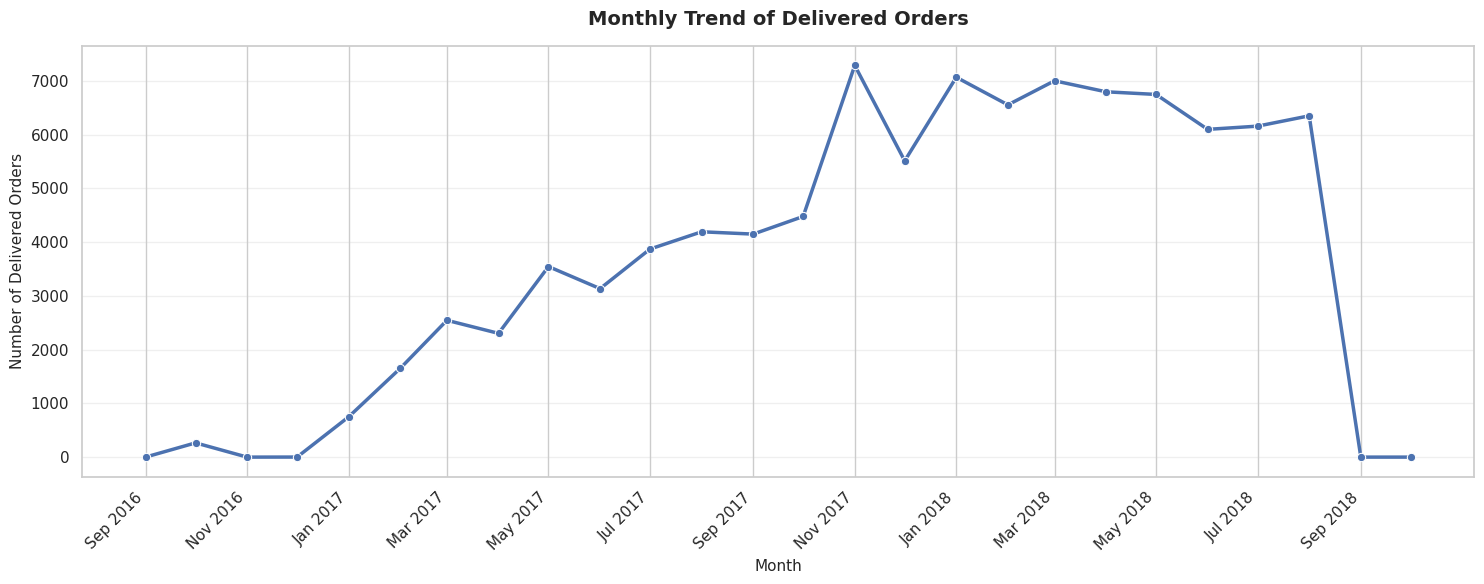

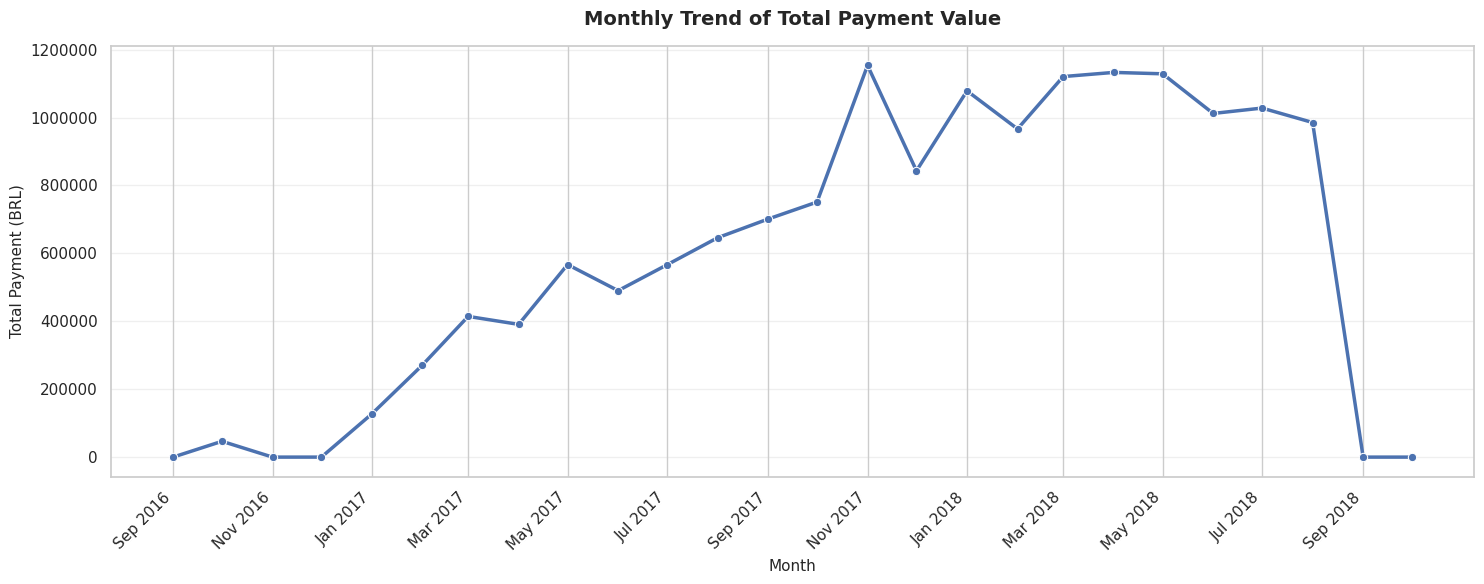

In [ ]:
monthly_period = pd.date_range(
    start='2016-09-01',
    end='2018-10-01',
    freq='MS'
)

monthly_visual = (
    monthly_orders_clean
    .set_index('order_purchase_timestamp')
    .resample('MS')
    .agg(
        total_orders=('order_id', 'nunique'),
        total_payment=('payment_value', 'sum')
    )
    .reindex(monthly_period, fill_value=0)
    .rename_axis('month')
    .reset_index()
)

monthly_visual['month_label'] = (
    monthly_visual['month'].dt.strftime('%b %Y')
)

# Visualisasi 1A: Tren jumlah pesanan delivered
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_visual,
    x='month',
    y='total_orders',
    marker='o',
    linewidth=2.5
)

plt.title(
    'Monthly Trend of Delivered Orders',
    fontweight='bold',
    pad=15
)
plt.xlabel('Month')
plt.ylabel('Number of Delivered Orders')
plt.xticks(
    monthly_visual['month'][::2],
    monthly_visual['month_label'][::2],
    rotation=45,
    ha='right'
)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# Visualisasi 1B: Tren total nilai pembayaran bulanan
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_visual,
    x='month',
    y='total_payment',
    marker='o',
    linewidth=2.5
)

plt.title(
    'Monthly Trend of Total Payment Value',
    fontweight='bold',
    pad=15
)
plt.xlabel('Month')
plt.ylabel('Total Payment (BRL)')
plt.xticks(
    monthly_visual['month'][::2],
    monthly_visual['month_label'][::2],
    rotation=45,
    ha='right'
)
plt.ticklabel_format(
    style='plain',
    axis='y'
)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Insight:**

Berdasarkan visualisasi tren bulanan, jumlah pesanan delivered dan total nilai pembayaran menunjukkan pola peningkatan secara umum selama periode pengamatan. Aktivitas transaksi mulai berkembang lebih signifikan sejak awal 2017 dan mencapai performa tertinggi pada November 2017.

Pada November 2017 tercatat 7.289 pesanan delivered dengan total nilai pembayaran sebesar BRL 1.153.528,05. Setelah periode tersebut, aktivitas transaksi masih menunjukkan fluktuasi dengan nilai yang relatif tinggi hingga 2018.

Sementara itu, September 2016 menjadi bulan dengan aktivitas terendah di antara bulan yang memiliki pesanan delivered, yaitu satu pesanan dengan nilai pembayaran BRL 0,00. Perlu diperhatikan bahwa September dan Oktober 2018 tidak menunjukkan pesanan delivered karena transaksi delivered terakhir dalam dataset tercatat pada Agustus 2018.

Secara keseluruhan, visualisasi menunjukkan adanya perkembangan aktivitas transaksi Olist dari periode awal pengamatan hingga 2018, dengan November 2017 sebagai periode performa tertinggi berdasarkan jumlah pesanan dan total nilai pembayaran.



### Pertanyaan 2:

#### Visualisasi Distribusi dan Kontribusi Monetary Segmen RFM

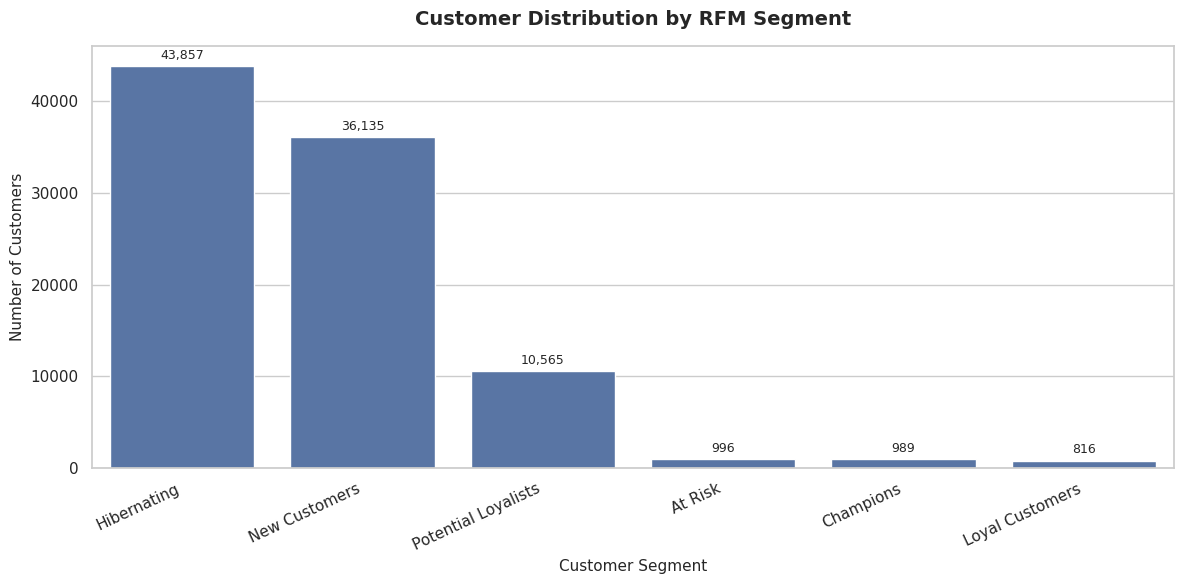

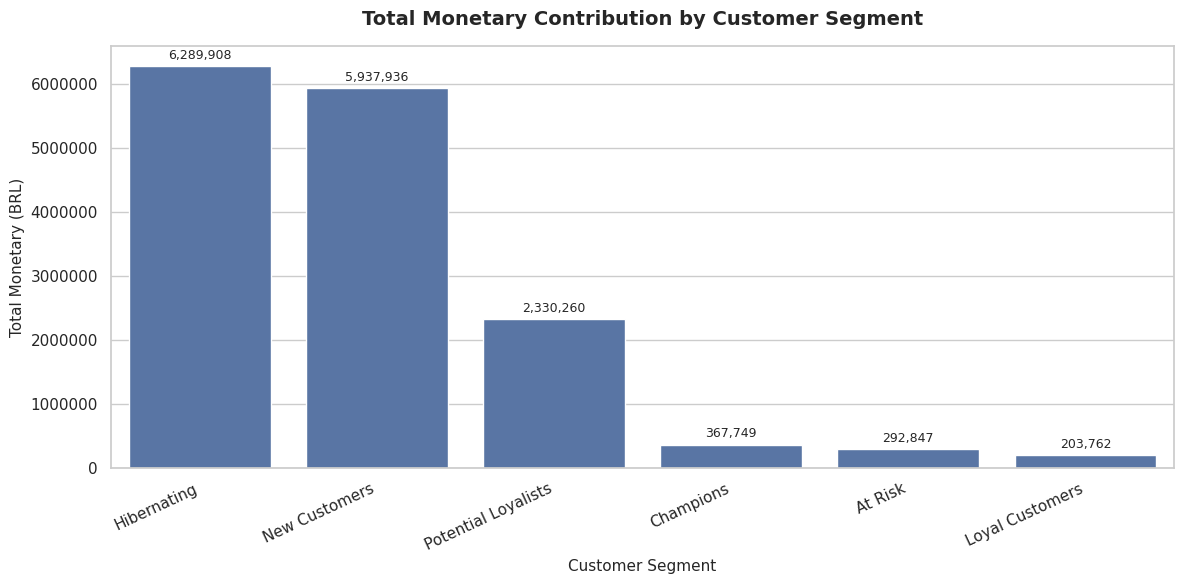

In [ ]:
segment_visual = segment_analysis.sort_values(
    'Jumlah_Pelanggan',
    ascending=False
).copy()


# Visualisasi 2A: Jumlah pelanggan pada setiap segmen
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=segment_visual,
    x='Customer_Segment',
    y='Jumlah_Pelanggan'
)

plt.title(
    'Customer Distribution by RFM Segment',
    fontweight='bold',
    pad=15
)
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=25, ha='right')

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='{:,.0f}',
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()


# Visualisasi 2B: Kontribusi Monetary setiap segmen
segment_monetary = segment_visual.sort_values(
    'Total_Monetary',
    ascending=False
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=segment_monetary,
    x='Customer_Segment',
    y='Total_Monetary'
)

plt.title(
    'Total Monetary Contribution by Customer Segment',
    fontweight='bold',
    pad=15
)
plt.xlabel('Customer Segment')
plt.ylabel('Total Monetary (BRL)')
plt.xticks(rotation=25, ha='right')
plt.ticklabel_format(
    style='plain',
    axis='y'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='{:,.0f}',
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

**Insight:**

Visualisasi distribusi pelanggan menunjukkan bahwa segmen Hibernating mendominasi keseluruhan pelanggan Olist, dengan jumlah 43.857 pelanggan atau 46,98% dari total pelanggan. Segmen ini juga memberikan kontribusi Monetary sebesar 40,78%.

Segmen New Customers menempati posisi kedua dengan 36.135 pelanggan atau 38,71% dan kontribusi Monetary sebesar 38,50%. Kondisi tersebut menunjukkan bahwa sebagian besar pelanggan masih memiliki frekuensi pembelian satu kali sehingga terdapat peluang untuk meningkatkan pembelian berulang.

Dari sisi kontribusi Monetary, segmen Hibernating dan New Customers memberikan kontribusi terbesar terhadap total nilai transaksi. Sementara itu, segmen Champions memiliki rata-rata Monetary tertinggi sebesar BRL 371,84 meskipun jumlah pelanggannya relatif kecil, yaitu 989 pelanggan.

Segmen At Risk juga perlu mendapatkan perhatian karena memiliki rata-rata Frequency sebesar 2,08 dan rata-rata Monetary sebesar BRL 294,02. Karakteristik tersebut menunjukkan bahwa pelanggan dalam segmen ini memiliki riwayat pembelian berulang sehingga berpotensi dipertahankan melalui strategi win-back.

Dengan demikian, strategi retensi dapat difokuskan pada reaktivasi pelanggan Hibernating, mendorong pembelian kedua pada New Customers, serta mempertahankan pelanggan Champions dan mengaktifkan kembali pelanggan At Risk.



### Pertanyaan 3:

#### Visualisasi Persebaran Pelanggan dan Pesanan per Negara Bagian

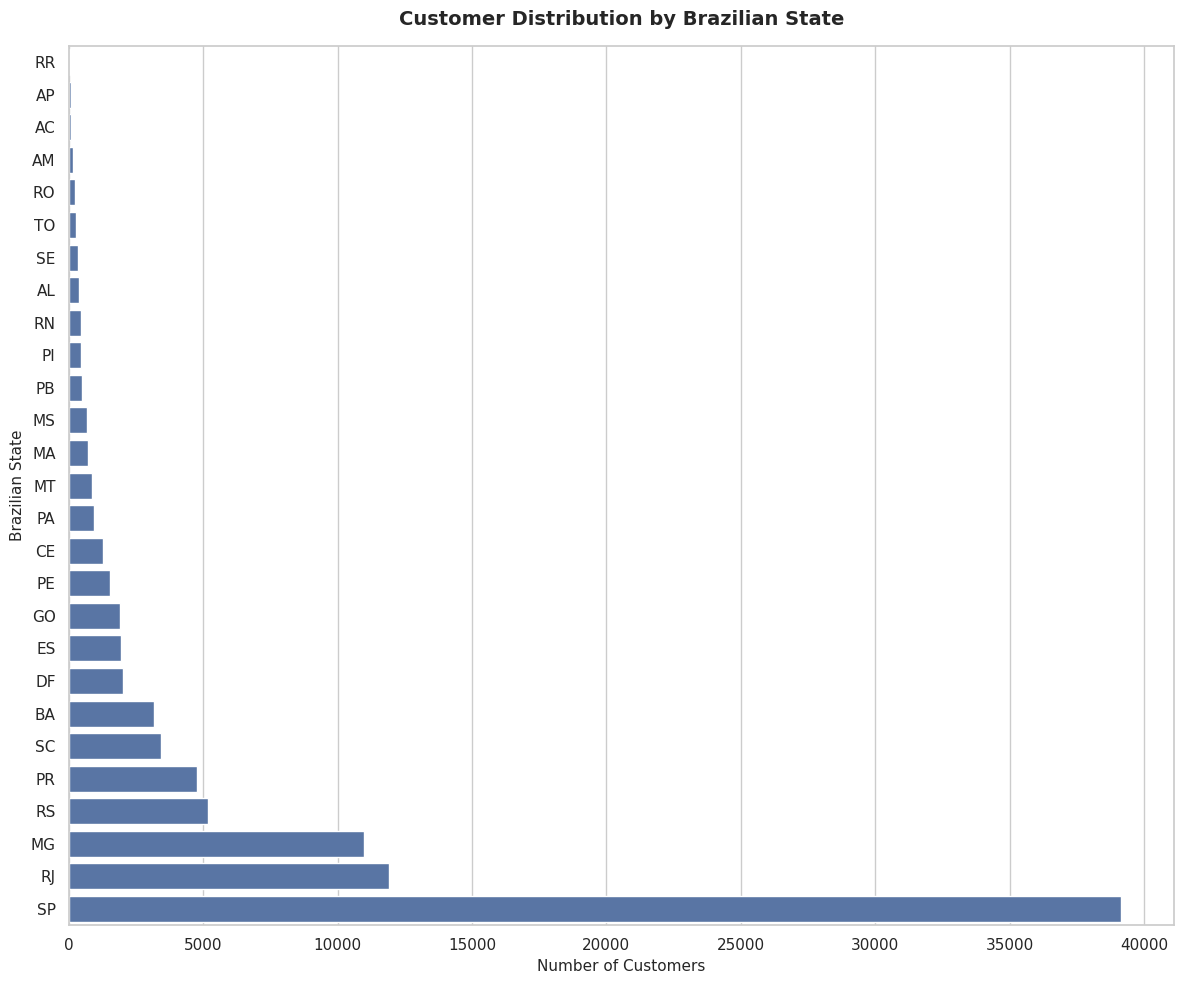

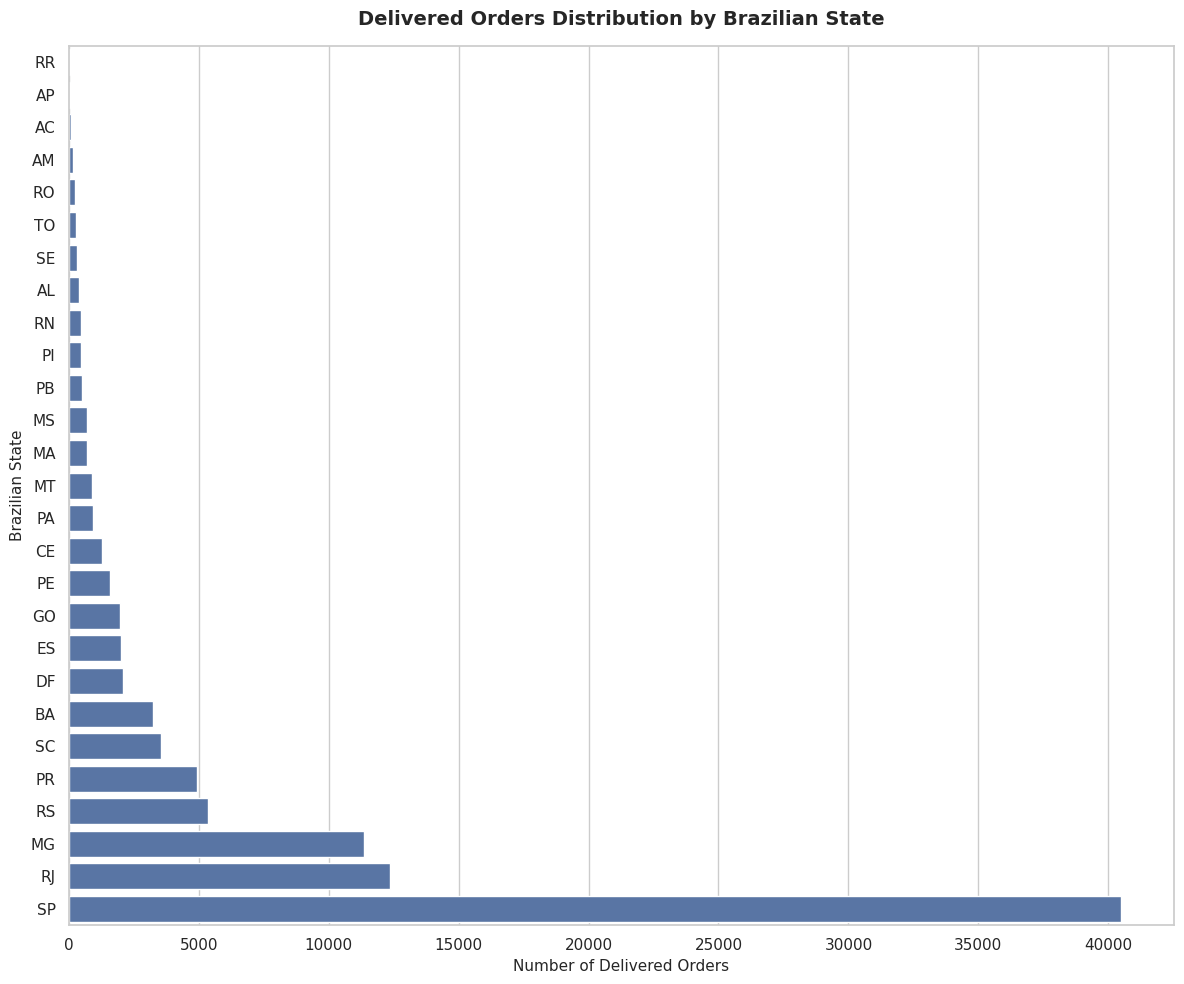

In [ ]:
state_customer_visual = state_analysis.sort_values(
    'Jumlah_Pelanggan',
    ascending=True
).copy()


# Visualisasi 3A: Distribusi pelanggan pada setiap state
plt.figure(figsize=(12, 10))

ax = sns.barplot(
    data=state_customer_visual,
    x='Jumlah_Pelanggan',
    y='customer_state'
)

plt.title(
    'Customer Distribution by Brazilian State',
    fontweight='bold',
    pad=15
)
plt.xlabel('Number of Customers')
plt.ylabel('Brazilian State')

plt.tight_layout()
plt.show()


# Mengurutkan state berdasarkan jumlah pesanan
state_order_visual = state_analysis.sort_values(
    'Jumlah_Pesanan',
    ascending=True
).copy()


# Visualisasi 3B: Distribusi pesanan delivered pada setiap state
plt.figure(figsize=(12, 10))

ax = sns.barplot(
    data=state_order_visual,
    x='Jumlah_Pesanan',
    y='customer_state'
)

plt.title(
    'Delivered Orders Distribution by Brazilian State',
    fontweight='bold',
    pad=15
)
plt.xlabel('Number of Delivered Orders')
plt.ylabel('Brazilian State')

plt.tight_layout()
plt.show()


**Insight:**

Visualisasi distribusi geografis menunjukkan bahwa aktivitas pelanggan dan pesanan Olist terkonsentrasi pada beberapa negara bagian di Brasil. São Paulo (SP) memiliki jumlah pelanggan dan pesanan delivered tertinggi, yaitu 39.156 pelanggan dan 40.501 pesanan.

Rio de Janeiro (RJ) menempati posisi kedua dengan 11.917 pelanggan dan 12.350 pesanan, sedangkan Minas Gerais (MG) berada di posisi ketiga dengan 11.001 pelanggan dan 11.354 pesanan.

Ketiga negara bagian tersebut secara keseluruhan mencakup 66,46% dari total pelanggan dan 66,55% dari total pesanan delivered. Hal ini menunjukkan bahwa sebagian besar aktivitas transaksi Olist berasal dari tiga wilayah tersebut.

Sebaliknya, Roraima (RR) memiliki jumlah pelanggan paling sedikit, yaitu 40 pelanggan dengan 41 pesanan. Beberapa negara bagian lainnya juga memiliki kontribusi pelanggan dan pesanan yang relatif rendah dibandingkan wilayah dengan aktivitas tertinggi.

Berdasarkan hasil tersebut, São Paulo, Rio de Janeiro, dan Minas Gerais dapat menjadi prioritas dalam mempertahankan serta mengoptimalkan pasar yang sudah memiliki basis pelanggan besar. Sementara itu, wilayah dengan jumlah pelanggan lebih rendah dapat dipertimbangkan untuk pengembangan pasar melalui strategi pemasaran dan perluasan jangkauan layanan.



## Analisis Lanjutan (Opsional)

### Analisis Hubungan Frekuensi Pembelian dengan Nilai Transaksi

Hubungan Frekuensi Pembelian dan Nilai Transaksi:


,Frequency,Jumlah_Pelanggan,Rata_Rata_Monetary,Median_Monetary,Total_Monetary
0,1,90557,160.76,105.39,"14,558,104.56"
1,2,2573,291.03,218.82,"748,808.38"
2,3,181,433.40,331.11,"78,445.86"
3,4,28,788.80,537.72,"22,086.28"
4,5,9,734.18,603.90,"6,607.63"
5,6,5,703.31,826.32,"3,516.57"
6,7,3,946.85,959.01,"2,840.56"
7,9,1,"1,172.66","1,172.66","1,172.66"
8,15,1,879.27,879.27,879.27


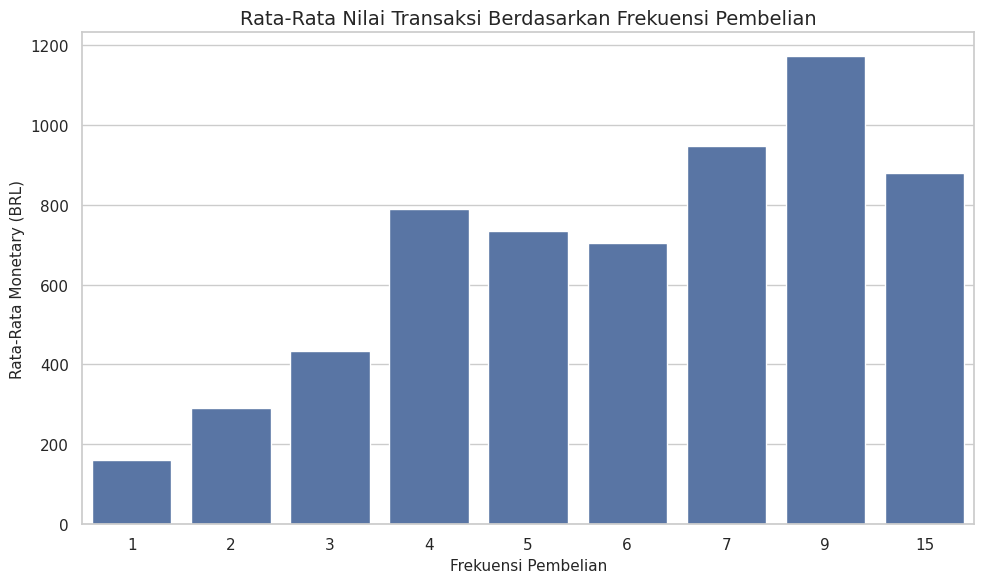

In [ ]:
# Analisis hubungan Frequency dan Monetary

frequency_monetary = rfm.groupby('Frequency').agg(
    Jumlah_Pelanggan=('customer_unique_id', 'nunique'),
    Rata_Rata_Monetary=('Monetary', 'mean'),
    Median_Monetary=('Monetary', 'median'),
    Total_Monetary=('Monetary', 'sum')
).reset_index()

print("Hubungan Frekuensi Pembelian dan Nilai Transaksi:")
display(frequency_monetary)

# Visualisasi
plt.figure(figsize=(10, 6))

sns.barplot(
    data=frequency_monetary,
    x='Frequency',
    y='Rata_Rata_Monetary'
)

plt.title('Rata-Rata Nilai Transaksi Berdasarkan Frekuensi Pembelian')
plt.xlabel('Frekuensi Pembelian')
plt.ylabel('Rata-Rata Monetary (BRL)')
plt.tight_layout()
plt.show()

### Analisis Rata-Rata Nilai Pembayaran Berdasarkan Negara Bagian

Rata-Rata Nilai Pembayaran Berdasarkan Negara Bagian:


,customer_state,Jumlah_Pesanan,Total_Payment,Rata_Rata_Payment
14,PB,517,"137,834.65",266.60
0,AC,80,"19,586.25",244.83
3,AP,67,"16,141.81",240.92
1,AL,397,"94,195.79",237.27
20,RO,243,"56,975.70",234.47
13,PA,946,"212,027.55",224.13
16,PI,476,"105,272.17",221.16
21,RR,41,"9,039.52",220.48
26,TO,274,"60,007.37",219.00
19,RN,474,"100,728.30",212.51


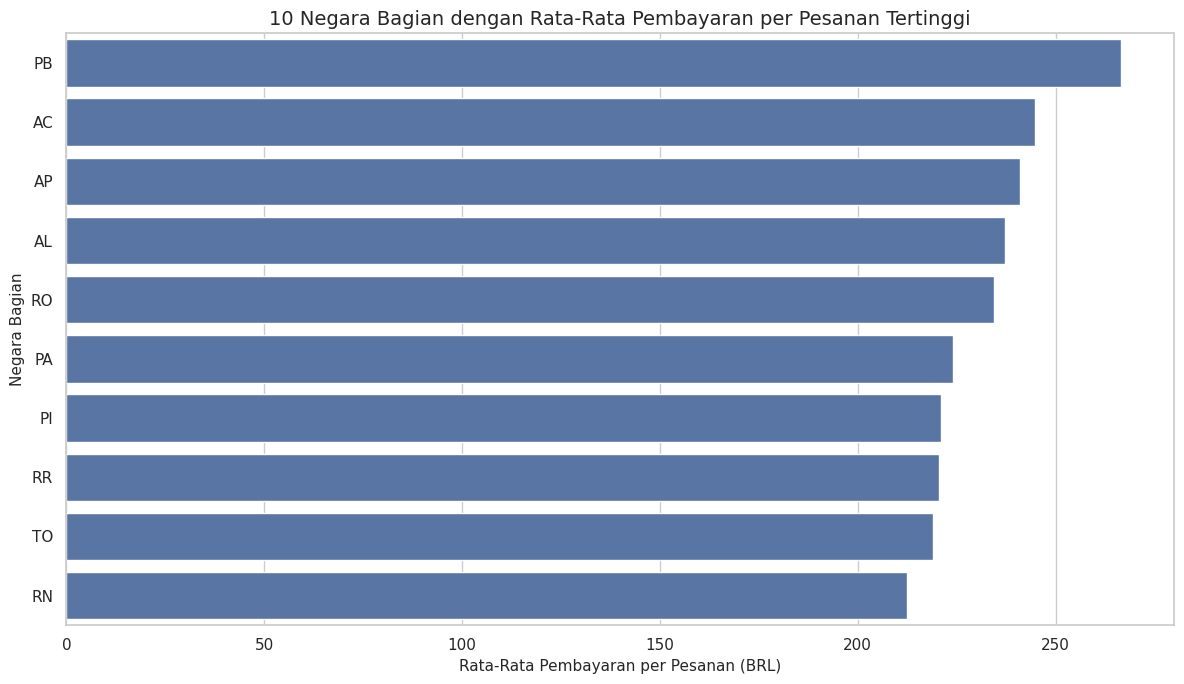

In [ ]:
# Menggabungkan data geografis dengan nilai pembayaran per pesanan

state_payment = geographic_data.merge(
    order_payment,
    on='order_id',
    how='left'
)

# Menghitung performa pembayaran setiap negara bagian
state_payment_analysis = state_payment.groupby('customer_state').agg(
    Jumlah_Pesanan=('order_id', 'nunique'),
    Total_Payment=('payment_value', 'sum'),
    Rata_Rata_Payment=('payment_value', 'mean')
).reset_index()

state_payment_analysis = state_payment_analysis.sort_values(
    by='Rata_Rata_Payment',
    ascending=False
)

print("Rata-Rata Nilai Pembayaran Berdasarkan Negara Bagian:")
display(state_payment_analysis.head(10))

# Visualisasi 10 negara bagian dengan rata-rata pembayaran tertinggi
plt.figure(figsize=(12, 7))

sns.barplot(
    data=state_payment_analysis.head(10),
    x='Rata_Rata_Payment',
    y='customer_state'
)

plt.title('10 Negara Bagian dengan Rata-Rata Pembayaran per Pesanan Tertinggi')
plt.xlabel('Rata-Rata Pembayaran per Pesanan (BRL)')
plt.ylabel('Negara Bagian')
plt.tight_layout()
plt.show()

### Insight Analisis Lanjutan

**Analisis 1 — Hubungan Frekuensi Pembelian dan Nilai Transaksi**
- Pelanggan dengan satu kali pembelian memiliki rata-rata Monetary sebesar **BRL 160,76**, sedangkan pelanggan dengan dua kali pembelian memiliki rata-rata sebesar **BRL 291,03**. Pada pelanggan dengan tiga kali pembelian, rata-rata Monetary meningkat menjadi **BRL 433,40**.
- Secara umum, hasil tersebut menunjukkan bahwa pelanggan dengan frekuensi pembelian lebih tinggi cenderung memiliki akumulasi nilai transaksi yang lebih besar, terutama pada kelompok dengan satu hingga tiga pesanan.
- Kelompok pelanggan dengan frekuensi pembelian empat kali atau lebih memiliki jumlah anggota yang jauh lebih sedikit. Oleh karena itu, nilai rata-rata pada kelompok tersebut lebih mudah dipengaruhi oleh karakteristik beberapa pelanggan dan perlu diinterpretasikan secara hati-hati.
- Pelanggan dengan satu kali pembelian tetap menyumbang total Monetary terbesar, yaitu **BRL 14.558.104,56**, karena jumlah kelompok ini sangat dominan, yaitu 90.557 pelanggan.

**Analisis 2 — Rata-Rata Nilai Pembayaran Berdasarkan Negara Bagian**
- Negara bagian **Paraíba (PB)** memiliki rata-rata nilai pembayaran per pesanan tertinggi di antara seluruh negara bagian, yaitu **BRL 266,60** dari 517 pesanan.
- Beberapa negara bagian lain seperti Acre (AC) dan Amapá (AP) juga memiliki rata-rata pembayaran yang relatif tinggi, masing-masing sebesar **BRL 244,83** dan **BRL 240,92**, tetapi jumlah pesanannya relatif lebih sedikit, yaitu 80 dan 67 pesanan.
- Temuan ini menunjukkan bahwa wilayah dengan rata-rata pembayaran per pesanan tertinggi tidak selalu merupakan wilayah dengan jumlah pelanggan dan pesanan terbesar. Oleh karena itu, evaluasi potensi pasar perlu mempertimbangkan rata-rata nilai pembayaran sekaligus volume transaksi.
- Rata-rata pembayaran per pesanan tidak dapat langsung diartikan sebagai keuntungan atau daya beli seluruh penduduk di suatu wilayah, karena analisis ini hanya menggambarkan transaksi pelanggan Olist yang berstatus delivered.


## Conclusion & Recommendation

### Kesimpulan

**Conclusion Pertanyaan 1:**

Berdasarkan analisis tren penjualan, performa transaksi Olist menunjukkan peningkatan yang cukup signifikan sejak akhir tahun 2016 hingga mencapai puncaknya pada November 2017. Pada bulan tersebut, jumlah pesanan berstatus delivered mencapai 7.289 pesanan dengan total nilai pembayaran sebesar BRL 1.153.528,05. Sementara itu, September 2016 menjadi bulan dengan performa terendah di antara bulan yang memiliki transaksi, yaitu hanya satu pesanan dengan total pembayaran BRL 0,00. Data juga menunjukkan bahwa pesanan berstatus delivered terakhir tercatat pada Agustus 2018.

**Conclusion Pertanyaan 2:**

Hasil segmentasi RFM menunjukkan bahwa mayoritas pelanggan Olist berada pada segmen Hibernating, sebanyak 43.857 pelanggan atau 46,98% dari keseluruhan pelanggan, dengan kontribusi nilai transaksi sebesar 40,78%. Segmen New Customers juga memiliki proporsi besar, yaitu 36.135 pelanggan atau 38,71%, dengan kontribusi Monetary sebesar 38,50%. Di sisi lain, segmen Champions memiliki rata-rata Monetary tertinggi sebesar BRL 371,84. Hal ini menunjukkan bahwa Olist perlu memperhatikan strategi aktivasi pembelian ulang, mempertahankan pelanggan bernilai tinggi, serta mengaktifkan kembali pelanggan yang sudah lama tidak melakukan transaksi.

**Conclusion Pertanyaan 3:**

Persebaran pelanggan dan pesanan Olist menunjukkan konsentrasi terbesar pada negara bagian São Paulo (SP), Rio de Janeiro (RJ), dan Minas Gerais (MG). Ketiga wilayah tersebut mencakup sekitar 66,46% dari keseluruhan pelanggan dan 66,55% dari total pesanan delivered. São Paulo menjadi wilayah dengan jumlah pelanggan dan pesanan tertinggi, sedangkan Roraima (RR) memiliki jumlah pelanggan dan pesanan terendah. Temuan ini menunjukkan bahwa ketiga wilayah dengan kontribusi terbesar merupakan pasar utama Olist, sementara wilayah dengan kontribusi lebih rendah dapat menjadi sasaran evaluasi dan pengembangan pasar berikutnya.

### Rekomendasi Action Items

**Rekomendasi Action Item:**
1. Meningkatkan Retensi Pelanggan: Mengembangkan program reaktivasi untuk segmen Hibernating melalui promosi yang relevan, voucher pembelian ulang, dan kampanye pemasaran yang ditargetkan berdasarkan riwayat transaksi pelanggan.
2. Mendorong Pembelian Kedua: Menyusun strategi customer engagement untuk segmen New Customers, seperti pemberian insentif pada transaksi berikutnya, rekomendasi produk, serta komunikasi setelah pembelian untuk meningkatkan kemungkinan pembelian ulang.
3. Mempertahankan Pelanggan Bernilai Tinggi: Memberikan program loyalitas, penawaran eksklusif, dan pengalaman belanja yang lebih personal kepada pelanggan Champions dan Loyal Customers agar hubungan jangka panjang dengan pelanggan tetap terjaga.
4. Mengoptimalkan Pasar Utama: Mempertahankan dan meningkatkan kualitas layanan di São Paulo, Rio de Janeiro, dan Minas Gerais melalui optimalisasi distribusi, pengelolaan stok, serta peningkatan pengalaman pelanggan karena ketiga wilayah tersebut memiliki kontribusi transaksi terbesar.
5. Mengevaluasi Potensi Pasar Regional: Melakukan evaluasi lebih lanjut terhadap wilayah dengan jumlah pelanggan dan pesanan yang relatif rendah untuk mengidentifikasi hambatan distribusi, jangkauan layanan, dan peluang pengembangan pasar.
6. Melakukan Monitoring Performa Bisnis: Mengembangkan dashboard analitik yang memantau tren pesanan, nilai pembayaran, segmentasi pelanggan RFM, serta persebaran geografis secara berkala agar perusahaan dapat mengambil keputusan berdasarkan data aktual.

In [3]:

import os
import shutil

# Membuat struktur folder submission
os.makedirs('/content/submission/dashboard', exist_ok=True)
os.makedirs('/content/submission/data', exist_ok=True)

# Daftar 9 dataset asli Olist
dataset_files = [
    'customers_dataset.csv',
    'orders_dataset.csv',
    'order_items_dataset.csv',
    'order_payments_dataset.csv',
    'order_reviews_dataset.csv',
    'products_dataset.csv',
    'sellers_dataset.csv',
    'geolocation_dataset.csv',
    'product_category_name_translation.csv'
]

# Menyalin dataset ke folder submission/data
for file in dataset_files:
    source = f'/content/{file}'
    destination = f'/content/submission/data/{file}'

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print(f'Berhasil disalin: {file}')
    else:
        print(f'File belum ditemukan: {file}')

print("\nStruktur folder submission berhasil disiapkan.")

Berhasil disalin: customers_dataset.csv
Berhasil disalin: orders_dataset.csv
Berhasil disalin: order_items_dataset.csv
Berhasil disalin: order_payments_dataset.csv
Berhasil disalin: order_reviews_dataset.csv
Berhasil disalin: products_dataset.csv
Berhasil disalin: sellers_dataset.csv
Berhasil disalin: geolocation_dataset.csv
Berhasil disalin: product_category_name_translation.csv

Struktur folder submission berhasil disiapkan.


In [6]:

import pandas as pd
import os

# ==========================================
# 1. MEMBACA DATASET LANGSUNG DARI FOLDER
# ==========================================

data_path = '/content/submission/data'
dashboard_path = '/content/submission/dashboard'

orders = pd.read_csv(
    f'{data_path}/orders_dataset.csv'
)

payments = pd.read_csv(
    f'{data_path}/order_payments_dataset.csv'
)

customers = pd.read_csv(
    f'{data_path}/customers_dataset.csv'
)

geolocation = pd.read_csv(
    f'{data_path}/geolocation_dataset.csv'
)

print("Seluruh dataset berhasil dibaca!")

# ==========================================
# 2. MEMILIH PESANAN DELIVERED
# ==========================================

orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp'],
    errors='coerce'
)

delivered = orders[
    orders['order_status'] == 'delivered'
].copy()

# ==========================================
# 3. MENGHITUNG TOTAL PEMBAYARAN PER ORDER
# ==========================================

payment_total = (
    payments.groupby('order_id', as_index=False)
    ['payment_value'].sum()
)

# ==========================================
# 4. MENGGABUNGKAN DATA PESANAN DAN PEMBAYARAN
# ==========================================

main_data = delivered[
    ['order_id', 'customer_id', 'order_purchase_timestamp']
].merge(
    payment_total,
    on='order_id',
    how='left'
)

# ==========================================
# 5. MENGGABUNGKAN DATA PELANGGAN
# ==========================================

main_data = main_data.merge(
    customers[
        ['customer_id', 'customer_unique_id', 'customer_state']
    ],
    on='customer_id',
    how='left'
)

# ==========================================
# 6. MENGHITUNG KOORDINAT GEOGRAFIS
# ==========================================

state_coordinates = (
    geolocation.groupby('geolocation_state')
    .agg(
        latitude=('geolocation_lat', 'mean'),
        longitude=('geolocation_lng', 'mean')
    )
    .reset_index()
)

# ==========================================
# 7. MENGGABUNGKAN KOORDINAT KE MAIN DATA
# ==========================================

main_data = main_data.merge(
    state_coordinates,
    left_on='customer_state',
    right_on='geolocation_state',
    how='left'
)

main_data.drop(
    columns=['geolocation_state'],
    inplace=True
)

# ==========================================
# 8. MENYIMPAN MAIN_DATA.CSV
# ==========================================

output_file = f'{dashboard_path}/main_data.csv'

main_data.to_csv(
    output_file,
    index=False
)

# ==========================================
# 9. MEMERIKSA HASIL
# ==========================================

print("\nMAIN_DATA.CSV BERHASIL DIBUAT!")
print("Jumlah baris:", len(main_data))
print("Jumlah kolom:", len(main_data.columns))
print("Jumlah order unik:", main_data['order_id'].nunique())
print("Lokasi file:", output_file)

display(main_data.head())


Seluruh dataset berhasil dibaca!

MAIN_DATA.CSV BERHASIL DIBUAT!
Jumlah baris: 96478
Jumlah kolom: 8
Jumlah order unik: 96478
Lokasi file: /content/submission/dashboard/main_data.csv


,order_id,customer_id,order_purchase_timestamp,payment_value,customer_unique_id,customer_state,latitude,longitude
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,38.71,7c396fd4830fd04220f754e42b4e5bff,SP,-23.155308,-47.084074
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,141.46,af07308b275d755c9edb36a90c618231,BA,-13.049361,-39.560649
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,179.12,3a653a41f6f9fc3d2a113cf8398680e8,GO,-16.577645,-49.334195
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,72.20,7c142cf63193a1473d2e66489a9ae977,RN,-5.856702,-35.990079
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,28.62,72632f0f9dd73dfee390c9b22eb56dd6,SP,-23.155308,-47.084074


In [7]:
import os

for root, dirs, files in os.walk('/content/submission'):
    level = root.replace('/content/submission', '').count(os.sep)
    indent = '    ' * level

    print(f'{indent}{os.path.basename(root)}/')

    for file in files:
        print(f'{indent}    {file}')

submission/
    data/
        sellers_dataset.csv
        order_reviews_dataset.csv
        order_payments_dataset.csv
        order_items_dataset.csv
        orders_dataset.csv
        products_dataset.csv
        product_category_name_translation.csv
        customers_dataset.csv
        geolocation_dataset.csv
    dashboard/
        main_data.csv


In [11]:
import shutil
import os

shutil.move(
    "/content/dashboard.py",
    "/content/submission/dashboard/dashboard.py"
)

print("Dashboard berhasil dipindahkan!")

Dashboard berhasil dipindahkan!


In [12]:
import os

# requirements.txt
requirements = """streamlit>=1.35,<2.0
pandas>=2.0,<3.0
numpy>=1.24,<3.0
plotly>=5.20,<7.0
"""

with open("/content/submission/requirements.txt", "w") as f:
    f.write(requirements)

# README.md
readme = """# Analisis Performa Penjualan, Perilaku Pelanggan, dan Distribusi Geografis pada Brazilian E-Commerce Olist

## Deskripsi
Proyek ini menganalisis data Brazilian E-Commerce Olist untuk memahami performa penjualan, perilaku pelanggan, dan distribusi geografis.

## Pertanyaan Bisnis
1. Bagaimana perkembangan jumlah pesanan terkirim dan nilai pembayaran setiap bulan?
2. Bagaimana karakteristik pelanggan berdasarkan segmentasi RFM?
3. Bagaimana persebaran pelanggan dan pesanan berdasarkan negara bagian di Brasil?

## Struktur Proyek
- data/: Dataset asli.
- dashboard/: Aplikasi dashboard Streamlit dan data hasil pengolahan.
- notebook.ipynb: Notebook analisis data.

## Menjalankan Dashboard
Install dependencies:

pip install -r requirements.txt

Jalankan aplikasi:

streamlit run dashboard/dashboard.py
"""

with open("/content/submission/README.md", "w") as f:
    f.write(readme)

print("requirements.txt dan README.md berhasil dibuat!")

requirements.txt dan README.md berhasil dibuat!
